--- Информация о датасете ---
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 80.7 KB
None

--- Статистики по числовым признакам ---
         survived

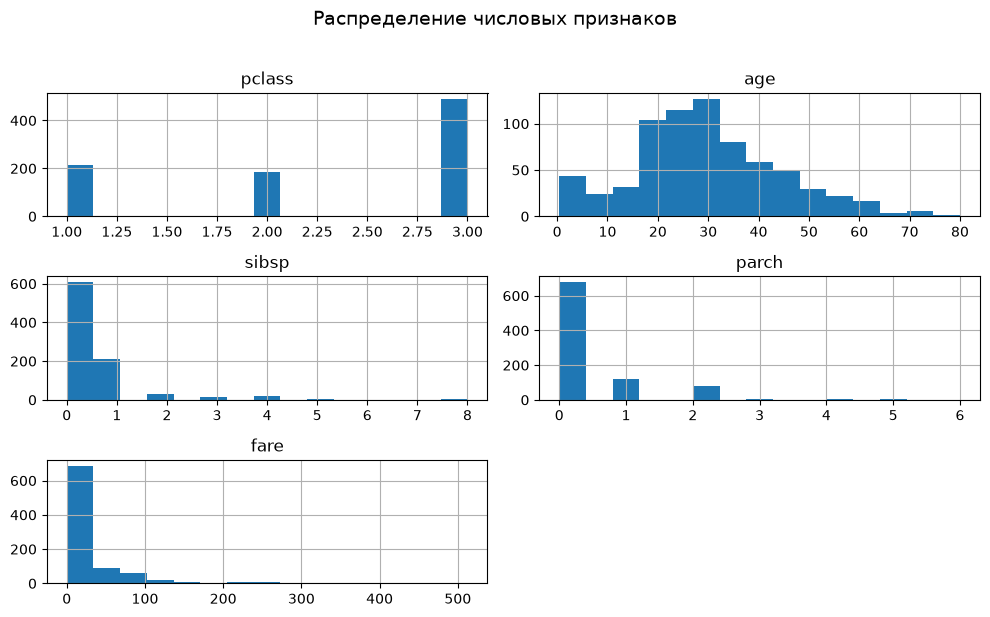

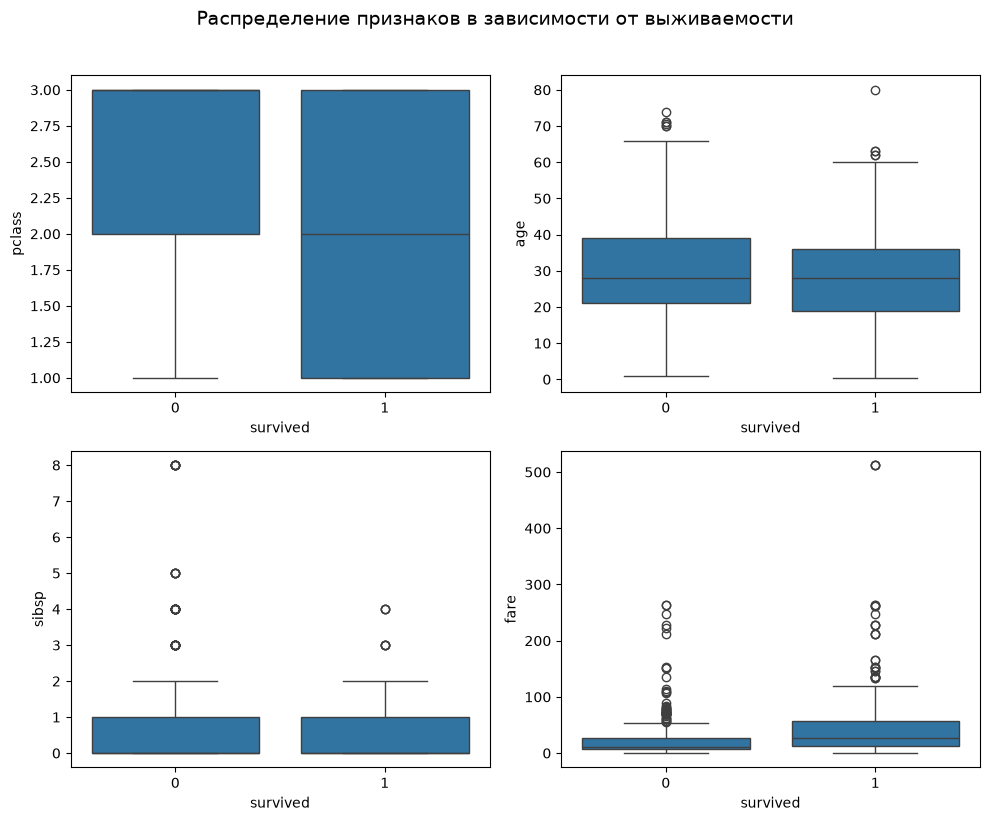

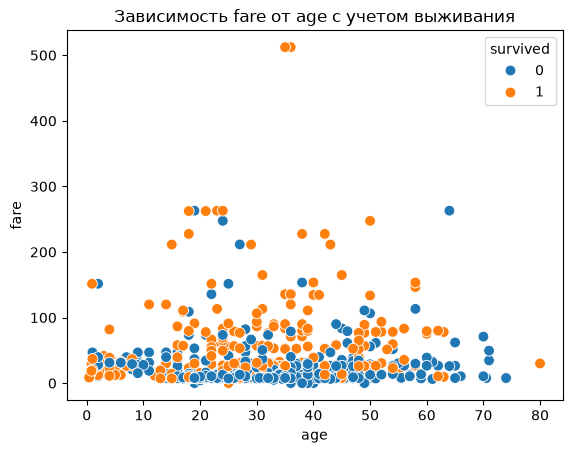

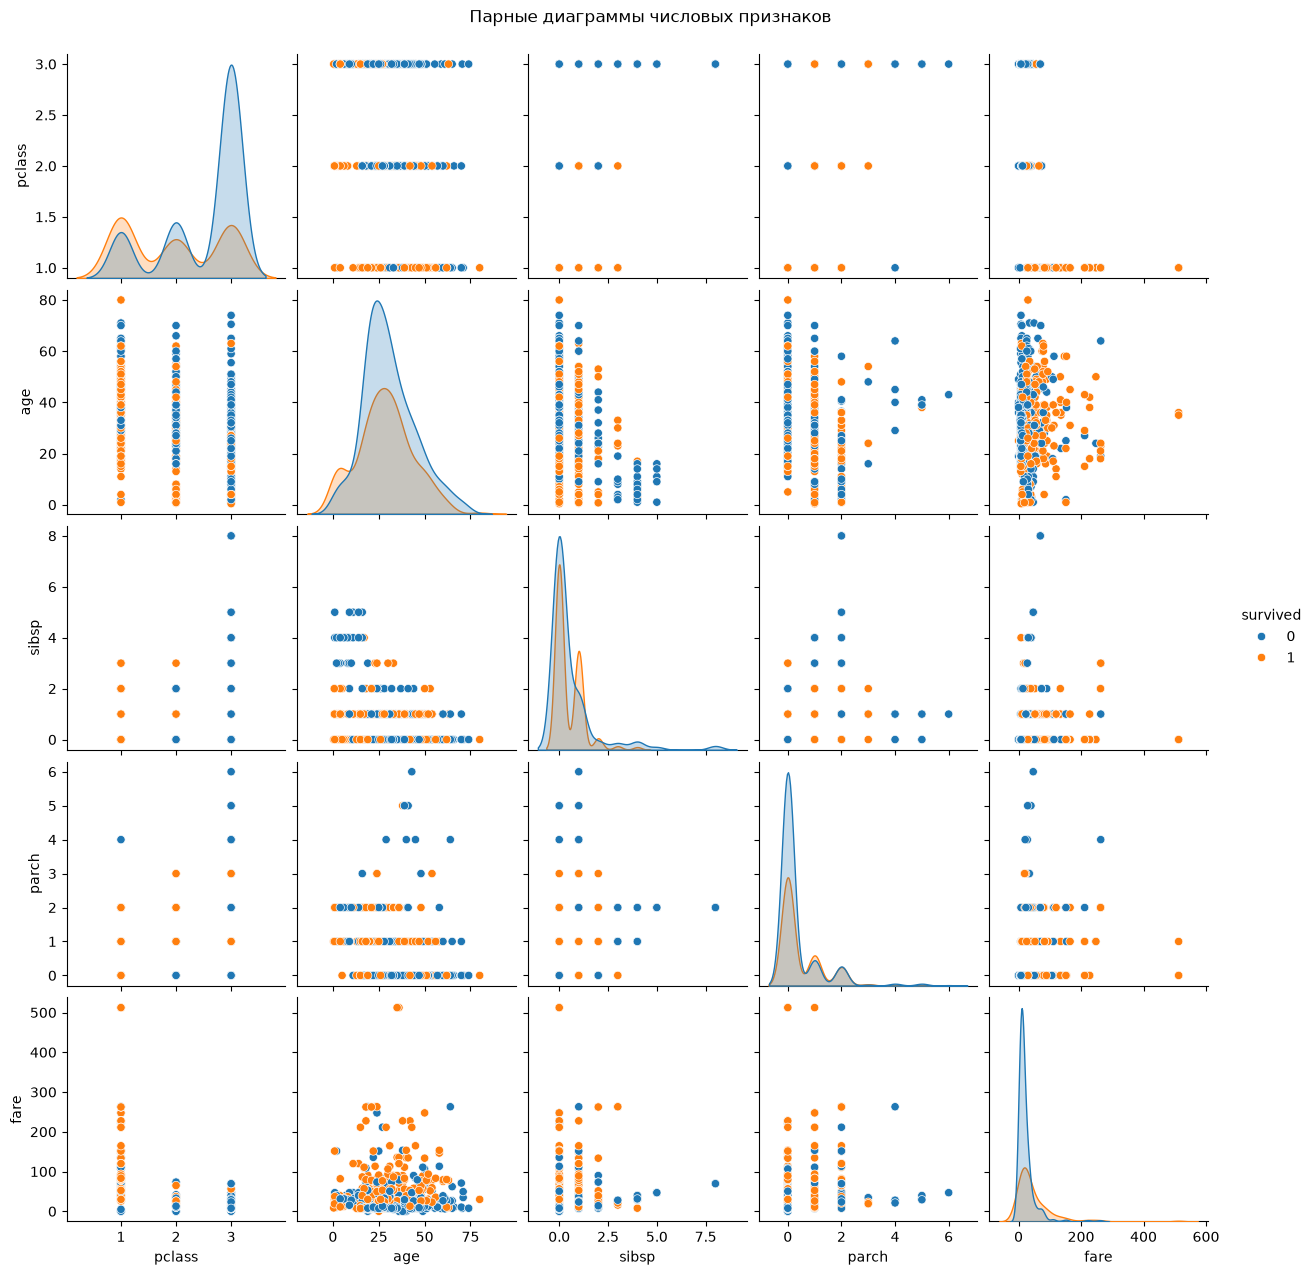

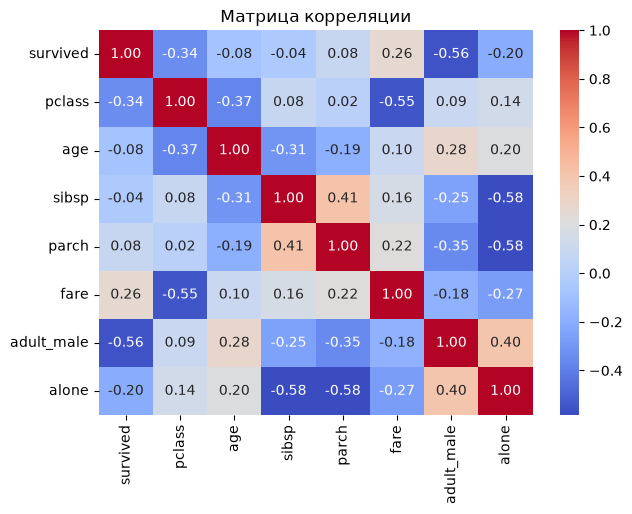

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Загрузка датасета
df = sns.load_dataset('titanic')

# 2.1 Первичный анализ данных
print("--- Информация о датасете ---")
print(df.info())
print("\n--- Статистики по числовым признакам ---")
print(df.describe())
print("\n--- Количество выживших и погибших ---")
print(df['survived'].value_counts())

# 2.2 Визуализация распределений
num_cols = ['pclass', 'age', 'sibsp', 'parch', 'fare']
df[num_cols].hist(figsize=(10, 6), bins=15)
# Используем suptitle для общего заголовка всей фигуры, y=1.02 чтобы он не наезжал на графики
plt.suptitle('Распределение числовых признаков', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

# Ящичные диаграммы по выживаемости
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
cols_to_plot = ['pclass', 'age', 'sibsp', 'fare']
for ax, col in zip(axes.ravel(), cols_to_plot):
    sns.boxplot(x='survived', y=col, data=df, ax=ax)
plt.suptitle('Распределение признаков в зависимости от выживаемости', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

# 2.3 Выявление зависимостей
# Диаграмма рассеяния
sns.scatterplot(data=df, x='age', y='fare', hue='survived', s=60)
plt.title('Зависимость fare от age с учетом выживания')
plt.show()

# Парные диаграммы (только числовые признаки + целевой)
# Примечание: pairplot автоматически удаляет строки с пропусками (например, в age)
sns.pairplot(df[['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare']], hue='survived')
plt.suptitle('Парные диаграммы числовых признаков', y=1.02)
plt.show()

# 2.4 Матрица корреляции
plt.figure(figsize=(7, 5))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Матрица корреляции')
plt.show()